## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Simon Mateo Barrios Mena " # @param {"type":"string"}
carnet = 1000113284 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
Una emprsa de transporte necesita gestionar una red de estaciones mediante grafos, permitiendo recorrerlas con BFS y DFS encontrar rutas cortas y agregar nuevas estaciones


## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

Funcionales:
1. Resgistrar estaciones y sus conexiones
2. Recorrer las estaciones mediante BFS y DFS
3. Permitir seleccionar una estacion inicial
4. Encontrar la ruta con menos conexiones
5. Agregar nuevas estaciones y conexiones
No Funcionales:
El programa debe desarrollarse en python.
Utilizar listas de adyacencia.
Evitar conexiones duplicadas.
Mostrar resultados claros y ordenados .
Ejecutar recorridos de manera eficiente.

## 3) Historias de usuario **[2 pts]**
HU1. Ver estaciones: Como usuario, quiero ver las conexiones.

* Criterio: Mostrar todas las estaciones.

HU2. Recorrer la red: Como usuario, quiero usar BFS y DFS.

* Criterio: Mostrar recorridos sin repetir estaciones.

HU3. Elegir inicio: Como usuario, quiero seleccionar una estación.

* Criterio: Validar que exista.

HU4. Buscar rutas: Como usuario, quiero encontrar la ruta más corta.

* Criterio: Mostrar ruta y cantidad de conexiones.

HU5. Agregar estaciones: Como administrador, quiero ampliar la red.

* Criterio: Agregar una estación con mínimo dos conexiones, sin duplicados.

## 4) Diagramas de flujo **[5 pts]**
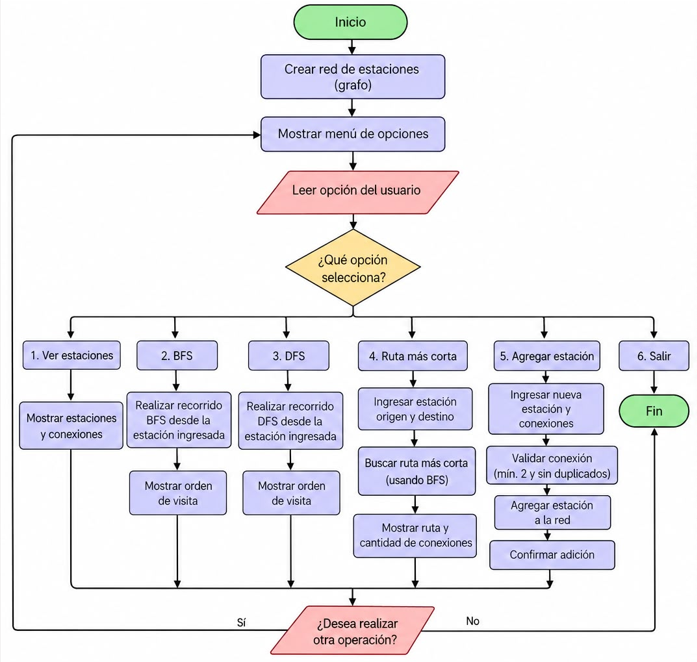

El programa crea una red de estaciones mediante un grafo. Permite visualizar conexiones, realizar recorridos BFS y DFS, buscar la ruta más corta y agregar estaciones. Finalmente, muestra los resultados de cada operación.

### 5) Análisis de complejidad **[15 pts]**
Justificación: El programa utiliza grafos, BFS y DFS para recorrer estaciones y encontrar rutas eficientes.

Función: T(n) = a(V + E) + b

* BFS: O(V + E)
* DFS: O(V + E)
* Ruta más corta: O(V + E)
* Agregar estación: O(V)

Mejor caso: O(1), cuando el origen y destino son iguales en la búsqueda de rutas.

Peor caso: O(V + E), cuando se debe recorrer toda la red.

Conclusión: La complejidad es lineal respecto al número de estaciones y conexiones, por lo que el programa es eficiente.
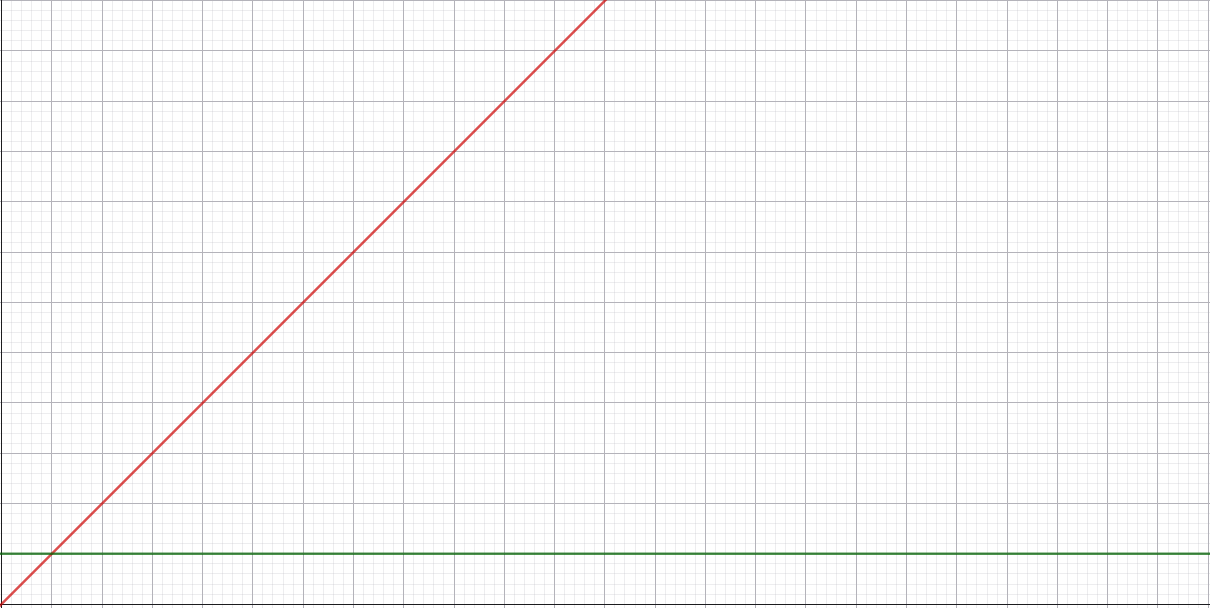

La gráfica representa la complejidad de la búsqueda de rutas mediante BFS. En el mejor caso, O(1), el tiempo es constante porque el origen y el destino son iguales. En el peor caso, O(n), el tiempo aumenta linealmente con la cantidad de estaciones y conexiones que deben recorrerse.


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [5]:
print("Punto 1")
grafo = {
    "Central": ["Norte", "Museo"],
    "Norte": ["Central", "Parque", "Universidad"],
    "Museo": ["Central", "Hospital"],
    "Parque": ["Norte"],
    "Universidad": ["Norte", "Terminal"],
    "Hospital": ["Museo", "Terminal"],
    "Terminal": ["Universidad", "Hospital"]
}

print("RED DE ESTACIONES")

for estacion, conexiones in grafo.items():
    print(estacion + ": " + ", ".join(conexiones))
print("Punto 2")
from collections import deque

def bfs(inicio):
    visitados = {inicio}
    cola = deque([(inicio, 0)])
    recorrido = []
    niveles = {}

    while cola:
        actual, nivel = cola.popleft()
        recorrido.append(actual)
        niveles[actual] = nivel

        for vecino in grafo[actual]:
            if vecino not in visitados:
                visitados.add(vecino)
                cola.append((vecino, nivel + 1))

    print("\nRECORRIDO BFS")
    print(" -> ".join(recorrido))

    for nivel in sorted(set(niveles.values())):
        estaciones = [
            e for e in recorrido
            if niveles[e] == nivel
        ]
        print("Nivel", nivel, ":", ", ".join(estaciones))

bfs("Central")
print("Punto 3")
def dfs(inicio):
    visitados = set()
    recorrido = []

    def visitar(estacion):
        visitados.add(estacion)
        recorrido.append(estacion)

        for vecino in grafo[estacion]:
            if vecino not in visitados:
                visitar(vecino)

    visitar(inicio)

    print("\nRECORRIDO DFS")
    print(" -> ".join(recorrido))

dfs("Central")
print("Punto 4")
inicio = input("\nIngrese la estacion inicial: ").strip()

if inicio in grafo:
    bfs(inicio)
    dfs(inicio)
else:
    print("Error: la estacion no existe.")
print("Punto 5")
def ruta_corta(origen, destino):
    if origen not in grafo or destino not in grafo:
        print("Error: estacion no encontrada.")
        return

    cola = deque([(origen, [origen])])
    visitados = {origen}

    while cola:
        actual, ruta = cola.popleft()

        if actual == destino:
            print("\nRUTA ENCONTRADA")
            print(" -> ".join(ruta))
            print("Cantidad de conexiones:", len(ruta) - 1)
            return

        for vecino in grafo[actual]:
            if vecino not in visitados:
                visitados.add(vecino)
                cola.append((vecino, ruta + [vecino]))

    print("No existe una ruta entre las estaciones.")


origen = input("\nEstacion de origen: ").strip()
destino = input("Estacion de destino: ").strip()

ruta_corta(origen, destino)
print("Punto 6")
def agregar_estacion(nombre, conexion1, conexion2):
    if not nombre or nombre in grafo:
        print("Error: la estacion ya existe o el nombre es invalido.")
        return

    if (conexion1 not in grafo or
        conexion2 not in grafo or
        conexion1 == conexion2):
        print("Error: conexiones invalidas.")
        return

    grafo[nombre] = [conexion1, conexion2]
    grafo[conexion1].append(nombre)
    grafo[conexion2].append(nombre)

    print("\nESTACION AGREGADA")
    print(nombre, "conectada con", conexion1, "y", conexion2)

    print("\nRED ACTUALIZADA")
    for estacion, conexiones in grafo.items():
        print(estacion + ": " + ", ".join(conexiones))


agregar_estacion("Aeropuerto", "Terminal", "Hospital")


bfs("Central")
dfs("Central")

ruta_corta("Central", "Aeropuerto")

Punto 1
RED DE ESTACIONES
Central: Norte, Museo
Norte: Central, Parque, Universidad
Museo: Central, Hospital
Parque: Norte
Universidad: Norte, Terminal
Hospital: Museo, Terminal
Terminal: Universidad, Hospital
Punto 2

RECORRIDO BFS
Central -> Norte -> Museo -> Parque -> Universidad -> Hospital -> Terminal
Nivel 0 : Central
Nivel 1 : Norte, Museo
Nivel 2 : Parque, Universidad, Hospital
Nivel 3 : Terminal
Punto 3

RECORRIDO DFS
Central -> Norte -> Parque -> Universidad -> Terminal -> Hospital -> Museo
Punto 4

Ingrese la estacion inicial: Museo

RECORRIDO BFS
Museo -> Central -> Hospital -> Norte -> Terminal -> Parque -> Universidad
Nivel 0 : Museo
Nivel 1 : Central, Hospital
Nivel 2 : Norte, Terminal
Nivel 3 : Parque, Universidad

RECORRIDO DFS
Museo -> Central -> Norte -> Parque -> Universidad -> Terminal -> Hospital
Punto 5

Estacion de origen: Museo
Estacion de destino: Centro
Error: estacion no encontrada.
Punto 6

ESTACION AGREGADA
Aeropuerto conectada con Terminal y Hospital

RED

## 7) Tests aplicados **[15 pts]**